In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

In [6]:
# Load the data

In [7]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [8]:
Data = Data.iloc[:, 1 :-13]
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21
...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63


In [9]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FPS                      10332 non-null  float64
 1   Frame Duration (ms)      10332 non-null  float64
 2   Min Frame Duration (ms)  10332 non-null  float64
 3   Max Frame Duration (ms)  10332 non-null  float64
 4   Avg Frame Duration (ms)  10332 non-null  float64
 5   Std Dev (ms)             10332 non-null  float64
 6   Entropy Framerate        10332 non-null  float64
dtypes: float64(7)
memory usage: 565.2 KB


In [10]:
Data.head(10)

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21
5,77.87,12.84,12.65,16.11,13.26,1.50,0.09
6,69.38,14.41,12.65,14.52,13.88,0.88,0.31
7,68.05,14.69,12.65,14.69,14.28,1.12,0.41
8,69.73,14.34,12.65,14.69,14.31,1.01,0.30
9,80.83,12.37,12.37,14.69,13.51,0.90,0.07


In [11]:
Data.shape

(10332, 7)

In [12]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [13]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,0
...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,1


In [14]:
# Select input features and target variable

In [15]:
X = Data.iloc[:, 0 :]
X.drop(['Labels'], axis=1, inplace=True)

In [16]:
y = Data['Labels']

In [17]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
# Fit a random forest regressor and get the feature importances

In [20]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [21]:
print(f'model score on training data: {rf.score(X_train, y_train)}')
print(f'model score on testing data: {rf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 0.9999988914869199


In [22]:
importances_rf = rf.feature_importances_
indices = np.argsort(importances_rf)[::-1]

In [23]:
# Get feature names
feature_names_rf = X.columns

In [24]:
# Sort features by importance
indices = np.argsort(importances_rf)[::-1]

In [25]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances_rf[indices[f]], feature_names_rf[indices[f]]))

Feature ranking:
1. feature 0 (0.520000) - FPS
2. feature 1 (0.480000) - Frame Duration (ms)
3. feature 6 (0.000000) - Entropy Framerate
4. feature 5 (0.000000) - Std Dev (ms)
5. feature 4 (0.000000) - Avg Frame Duration (ms)
6. feature 3 (0.000000) - Max Frame Duration (ms)
7. feature 2 (0.000000) - Min Frame Duration (ms)


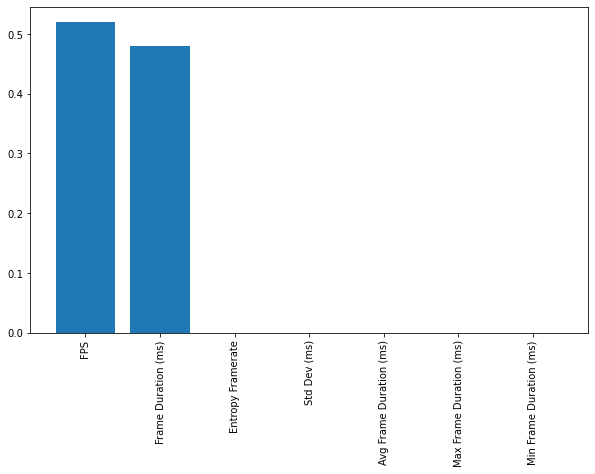

In [26]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_rf)), importances_rf[indices])
plt.xticks(range(len(importances_rf)), feature_names_rf[indices], rotation=90)
plt.show()

In [27]:
# Calculate permutation importances

In [28]:
result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

In [29]:
# Print feature ranking
sorted_idx = result.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result.importances_mean[i]:.3f} +/- {result.importances_std[i]:.3f}")

FPS             0.544 +/- 0.010
Frame Duration (ms) 0.463 +/- 0.009
Entropy Framerate 0.000 +/- 0.000
Std Dev (ms)    0.000 +/- 0.000
Avg Frame Duration (ms) 0.000 +/- 0.000
Max Frame Duration (ms) 0.000 +/- 0.000
Min Frame Duration (ms) 0.000 +/- 0.000


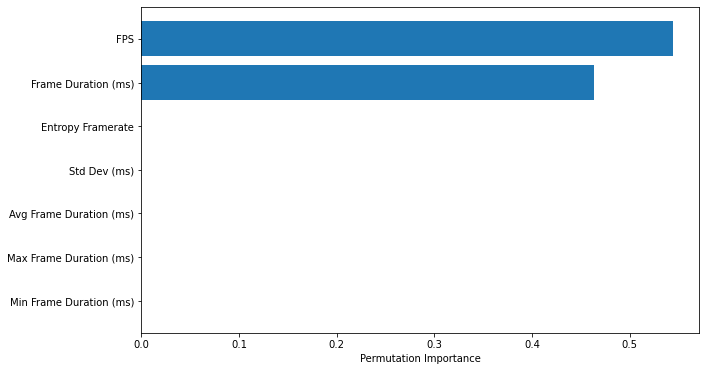

In [30]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [31]:
# Fit a linear regression model

In [32]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [33]:
print(f'model score on training data: {lr.score(X_train, y_train)}')
print(f'model score on testing data: {lr.score(X_test, y_test)}')

model score on training data: 0.8400626816378307
model score on testing data: 0.8444057078295611


In [34]:
# Get the coefficient values and feature names

In [35]:
coef_lr = lr.coef_

In [36]:
# Print the feature importance

In [37]:
feature_names_lr = X.columns

In [38]:
# Print the feature importance
print("Feature importance:")
for i in range(len(feature_names_lr)):
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
FPS: 0.444213
Frame Duration (ms): 0.076467
Min Frame Duration (ms): 0.018347
Max Frame Duration (ms): 0.028744
Avg Frame Duration (ms): 0.022871
Std Dev (ms): 0.014208
Entropy Framerate: 0.027419


In [39]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names_lr[i], abs(coef_lr[i])))

Feature importance:
FPS: 0.444213
Frame Duration (ms): 0.076467
Max Frame Duration (ms): 0.028744
Entropy Framerate: 0.027419
Avg Frame Duration (ms): 0.022871
Min Frame Duration (ms): 0.018347
Std Dev (ms): 0.014208


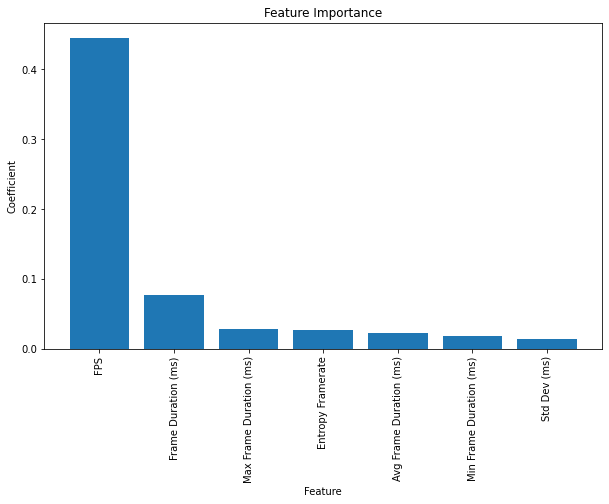

In [40]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names_lr[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [41]:
# Calculate permutation importances

In [42]:
result = permutation_importance(lr, X_test, y_test, n_repeats=10, random_state=42)

In [43]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lr[i], result.importances_mean[i]))

Permutation importances:
FPS: 1.772948
Frame Duration (ms): 0.041790
Entropy Framerate: 0.006655
Avg Frame Duration (ms): 0.003975
Min Frame Duration (ms): 0.003782
Std Dev (ms): 0.002941
Max Frame Duration (ms): 0.002853


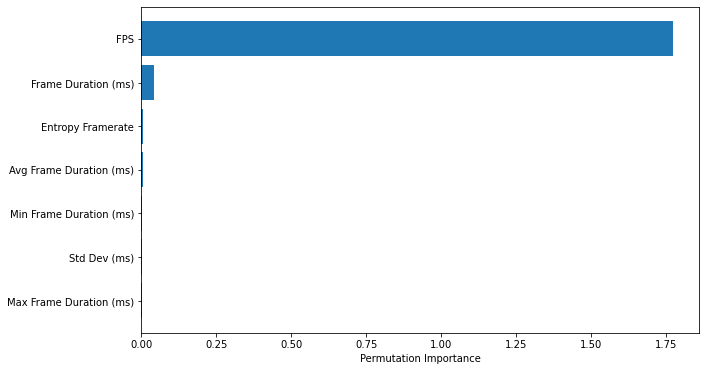

In [44]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [45]:
# Fit a Logistic Regression model

In [46]:
lor = LogisticRegression(max_iter= 1000)
lor.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [47]:
print(f'model score on training data: {lor.score(X_train, y_train)}')
print(f'model score on testing data: {lor.score(X_test, y_test)}')

model score on training data: 0.996249243799153
model score on testing data: 0.9966134494436382


In [48]:
# Get the coefficient values and feature names

In [49]:
coef_lor = lor.coef_[0]
feature_names_lor = X.columns

In [50]:
# Print the feature names and their absolute coefficient values in descending order
for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1]):
    print("%s: %f" % (name, value))

FPS: 11.405504
Frame Duration (ms): 1.898380
Max Frame Duration (ms): 0.872613
Min Frame Duration (ms): 0.635002
Std Dev (ms): 0.364220
Avg Frame Duration (ms): 0.218152
Entropy Framerate: 0.120044


In [51]:
# Sort features by absolute coefficient value
sorted_features = [name for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]
sorted_coefs = [value for name, value in sorted(zip(feature_names_lor, abs(coef_lor)), key=lambda x: -x[1])]

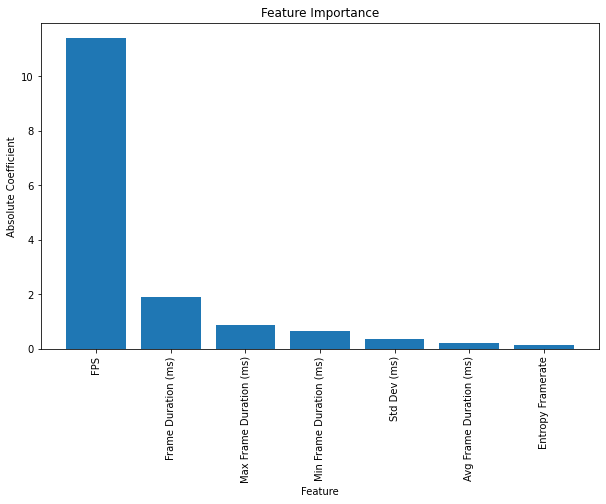

In [52]:
# Create bar plot of feature importance
plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefs)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Absolute Coefficient')
plt.title('Feature Importance')
plt.show()

In [53]:
# Calculate permutation importances

In [54]:
result = permutation_importance(lor, X_test, y_test, n_repeats=10, random_state=42)

In [55]:
# Print permutation importances
print("Permutation importances:")
for i in result.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names_lor[i], result.importances_mean[i]))

Permutation importances:
FPS: 0.407402
Frame Duration (ms): 0.006580
Max Frame Duration (ms): 0.001984
Min Frame Duration (ms): 0.001306
Entropy Framerate: 0.000194
Std Dev (ms): 0.000097
Avg Frame Duration (ms): -0.000387


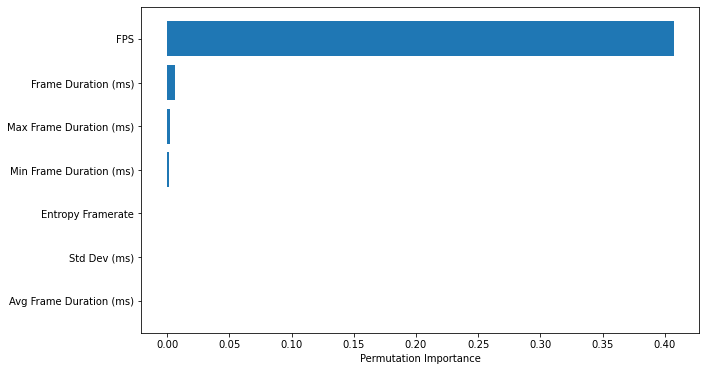

In [56]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [57]:
#Decision tree-based 

In [58]:
# Train a decision tree classifier on the original dataset

In [59]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [60]:
print(f'model score on training data: {clf.score(X_train, y_train)}')
print(f'model score on testing data: {clf.score(X_test, y_test)}')

model score on training data: 1.0
model score on testing data: 1.0


In [61]:
# Plot the feature importance

In [62]:
importance_clf = clf.feature_importances_
feature_names_clf = X.columns

In [63]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importance_clf})

In [64]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                   Feature  Importance
0                      FPS         1.0
1      Frame Duration (ms)         0.0
2  Min Frame Duration (ms)         0.0
3  Max Frame Duration (ms)         0.0
4  Avg Frame Duration (ms)         0.0
5             Std Dev (ms)         0.0
6        Entropy Framerate         0.0


In [65]:
sorted_idx = importance_clf.argsort()

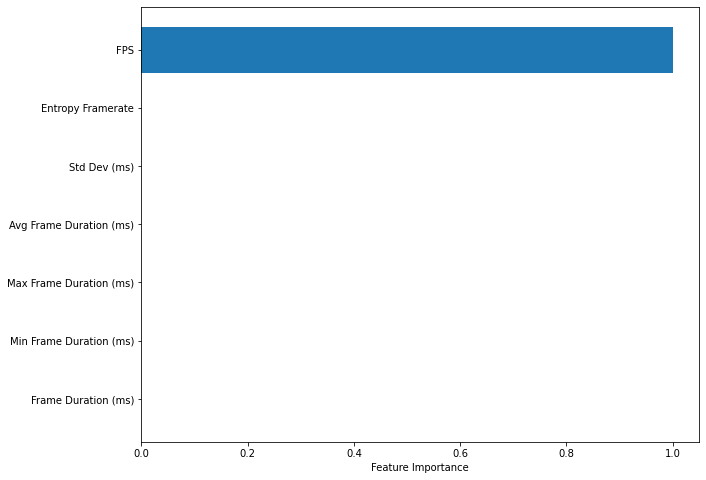

In [66]:
plt.figure(figsize = (10, 8))
plt.barh(range(len(sorted_idx)), importance_clf[sorted_idx])
plt.yticks(range(len(sorted_idx)), [feature_names_clf[i] for i in sorted_idx])
plt.xlabel('Feature Importance')
plt.show()

In [67]:
# Calculate permutation importance
perm_importance = permutation_importance(clf, X_train, y_train, n_repeats=10, random_state=42)

In [68]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [69]:
feature_importance

,Feature,Importance
0,FPS,0.438475
1,Frame Duration (ms),0.000000
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000


In [70]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                   Feature  Importance
0                      FPS    0.438475
1      Frame Duration (ms)    0.000000
2  Min Frame Duration (ms)    0.000000
3  Max Frame Duration (ms)    0.000000
4  Avg Frame Duration (ms)    0.000000
5             Std Dev (ms)    0.000000
6        Entropy Framerate    0.000000


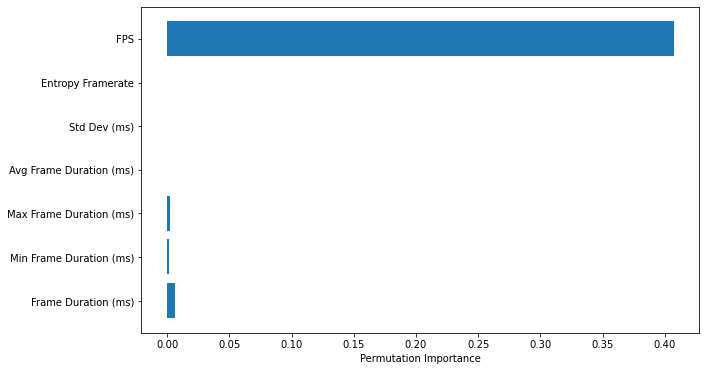

In [71]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [72]:
#Lasso regression

In [73]:
# Train a Lasso regression model on the original dataset

In [74]:
Lasso = Lasso(alpha=0.1)
Lasso.fit(X_train, y_train)

Lasso(alpha=0.1)

In [75]:
print(f'model score on training data: {Lasso.score(X_train, y_train)}')
print(f'model score on testing data: {Lasso.score(X_test, y_test)}')

model score on training data: 0.7723886674772339
model score on testing data: 0.773013269731321


In [76]:
# Get the absolute value of the regression coefficients

In [77]:
Lasso_abs = abs(Lasso.coef_)

In [78]:
Lasso_abs

array([0.32421594, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        ])

In [79]:
# Create a DataFrame to store the feature importance scores and names

In [80]:
feature_importance_Lasso = pd.DataFrame({'Feature_names': X.columns, 'Importance':Lasso_abs})

In [81]:
# Sort the features by importance and print the ranked list

In [82]:
feature_importance_Lasso = feature_importance_Lasso.sort_values('Importance', ascending=False)

In [83]:
feature_importance_Lasso

,Feature_names,Importance
0,FPS,0.324216
1,Frame Duration (ms),0.000000
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000


In [84]:
# Create a barplot of the feature importance scores>

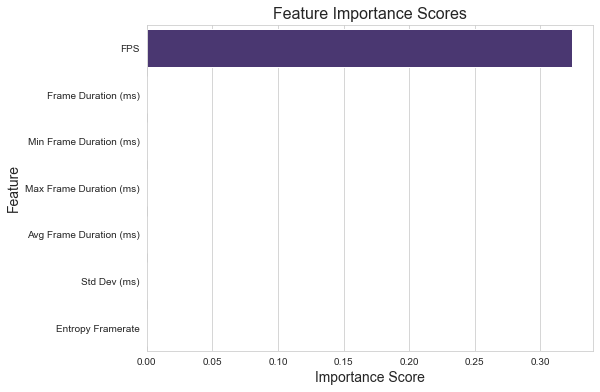

In [85]:
plt.figure(figsize=(8, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance_Lasso, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [86]:
# Calculate permutation importance
perm_importance_Lasso = permutation_importance(Lasso, X_train, y_train, n_repeats=10, random_state=42)

In [87]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance.importances_mean})

In [88]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                   Feature  Importance
0                      FPS    0.438475
1      Frame Duration (ms)    0.000000
2  Min Frame Duration (ms)    0.000000
3  Max Frame Duration (ms)    0.000000
4  Avg Frame Duration (ms)    0.000000
5             Std Dev (ms)    0.000000
6        Entropy Framerate    0.000000


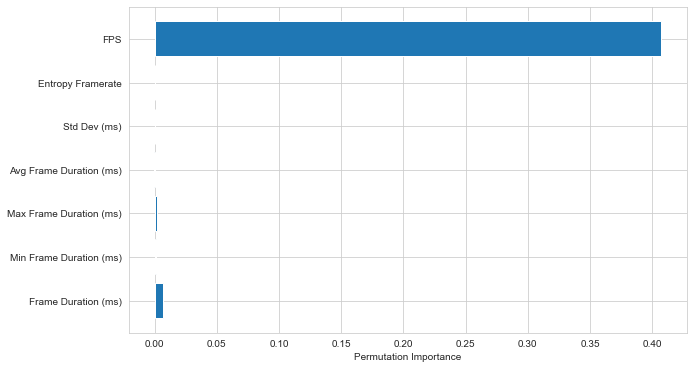

In [89]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [90]:
#XGBClassifier

In [91]:
from xgboost import XGBClassifier

In [92]:
# Instantiate XGBClassifier with default hyperparameters

In [93]:
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

In [94]:
# Use the built-in feature importance method to get feature importance scores
feat_importances_xgb = xgb.feature_importances_

In [95]:
feat_importances_xgb

array([1., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [96]:
# Create a dictionary mapping feature names to importance scores
feat_importances_dict = {feat: score for feat, score in zip(X.columns, feat_importances_xgb)}

In [97]:
feat_importances_dict

{'FPS': 1.0,
 'Frame Duration (ms)': 0.0,
 'Min Frame Duration (ms)': 0.0,
 'Max Frame Duration (ms)': 0.0,
 'Avg Frame Duration (ms)': 0.0,
 'Std Dev (ms)': 0.0,
 'Entropy Framerate': 0.0}

In [98]:
# Sort the ditionary in descending order of importance score
sorted_feat_importances = sorted(feat_importances_dict.items(), key=lambda x: x[1], reverse=True)

In [99]:
# Print the sorted feature importance scores
for feat, score in sorted_feat_importances:
    print(f'{feat}: {score}')

FPS: 1.0
Frame Duration (ms): 0.0
Min Frame Duration (ms): 0.0
Max Frame Duration (ms): 0.0
Avg Frame Duration (ms): 0.0
Std Dev (ms): 0.0
Entropy Framerate: 0.0


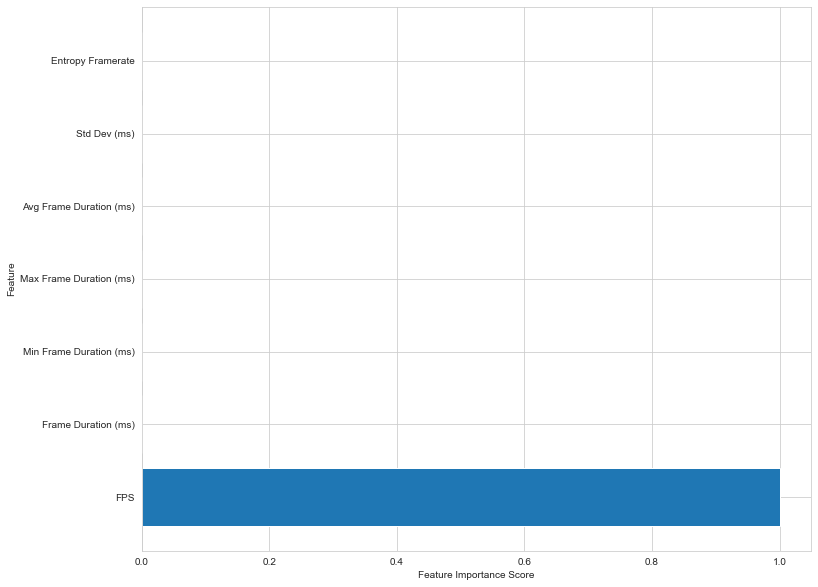

In [100]:
# Plot the feature importance scores as a horizontal bar chart
plt.figure(figsize = (12, 10))
plt.barh(range(len(feat_importances_xgb)), feat_importances_xgb)
plt.yticks(range(len(feat_importances_xgb)), X.columns)
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.show()

In [101]:
# Calculate permutation importance
perm_importance_xgb = permutation_importance(xgb, X_train, y_train, n_repeats=10, random_state=42)

In [102]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_xgb.importances_mean})

In [103]:
feature_importance 

,Feature,Importance
0,FPS,0.438475
1,Frame Duration (ms),0.000000
2,Min Frame Duration (ms),0.000000
3,Max Frame Duration (ms),0.000000
4,Avg Frame Duration (ms),0.000000
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.000000


In [104]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)
print(feature_importance)

                   Feature  Importance
0                      FPS    0.438475
1      Frame Duration (ms)    0.000000
2  Min Frame Duration (ms)    0.000000
3  Max Frame Duration (ms)    0.000000
4  Avg Frame Duration (ms)    0.000000
5             Std Dev (ms)    0.000000
6        Entropy Framerate    0.000000


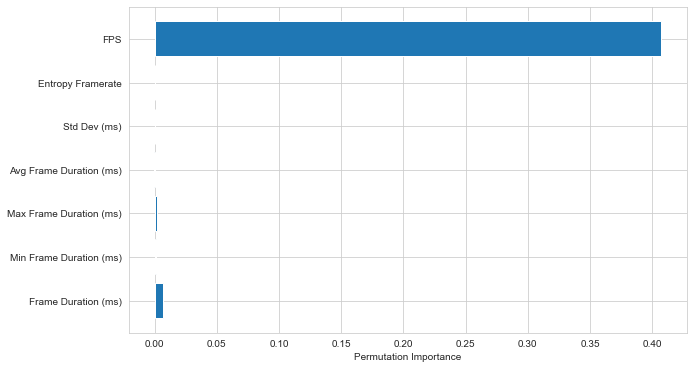

In [105]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_xgb.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [106]:
#Elastic Net Feature Importance

In [107]:
from sklearn.linear_model import ElasticNetCV

# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)

# Fit the model on training data
enet.fit(X_train, y_train)

# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])


FPS :  0.7618992604882096
Frame Duration (ms) :  0.11589225608001127
Entropy Framerate :  0.04716458147260131
Avg Frame Duration (ms) :  0.043926138633738
Min Frame Duration (ms) :  0.025120992481034204
Max Frame Duration (ms) :  0.005996770844405467
Std Dev (ms) :  0.0


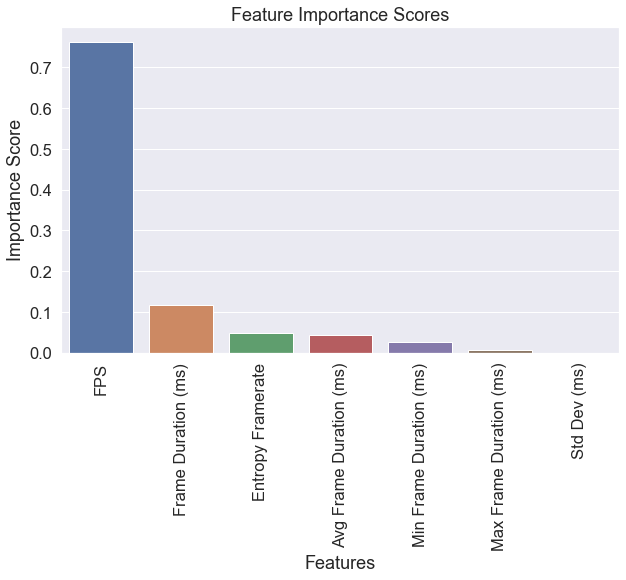

In [108]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [109]:
# Calculate permutation importance
perm_importance_enet = permutation_importance(enet, X_train, y_train, n_repeats=10, random_state=42)

In [110]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_enet = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_enet

,Feature,Importance
0,FPS,1.764391
1,Frame Duration (ms),0.041722
2,Min Frame Duration (ms),0.002163
3,Max Frame Duration (ms),0.000143
4,Avg Frame Duration (ms),0.005969
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.007277


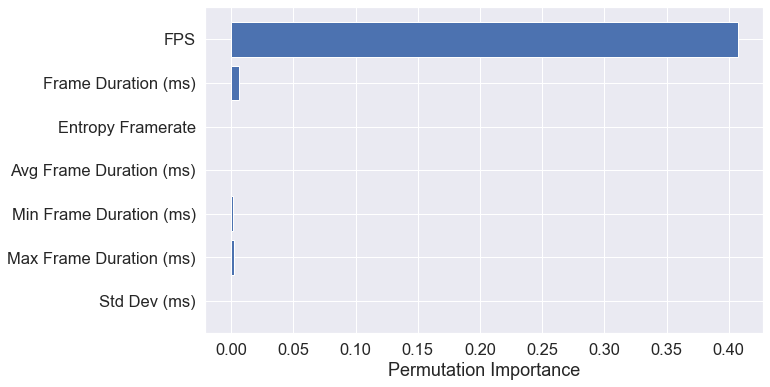

In [111]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [112]:
# Ridge model

In [113]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [114]:
# Predict on the testing data
y_pred = ridge.predict(X_test)

In [115]:
from sklearn.metrics import mean_squared_error

In [116]:
# Evaluate the model performance on testing data
mse = mean_squared_error(y_test, y_pred)
print("Mean squared error:", mse)

Mean squared error: 0.03395390984651221


In [117]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [118]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [119]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [120]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [121]:
sorted_features

[('FPS', 0.7027528135871671),
 ('Frame Duration (ms)', 0.12086776528895626),
 ('Max Frame Duration (ms)', 0.045147090821131816),
 ('Entropy Framerate', 0.04338657195567931),
 ('Avg Frame Duration (ms)', 0.03648826979001648),
 ('Min Frame Duration (ms)', 0.02907245778738645),
 ('Std Dev (ms)', 0.022285030769662432)]

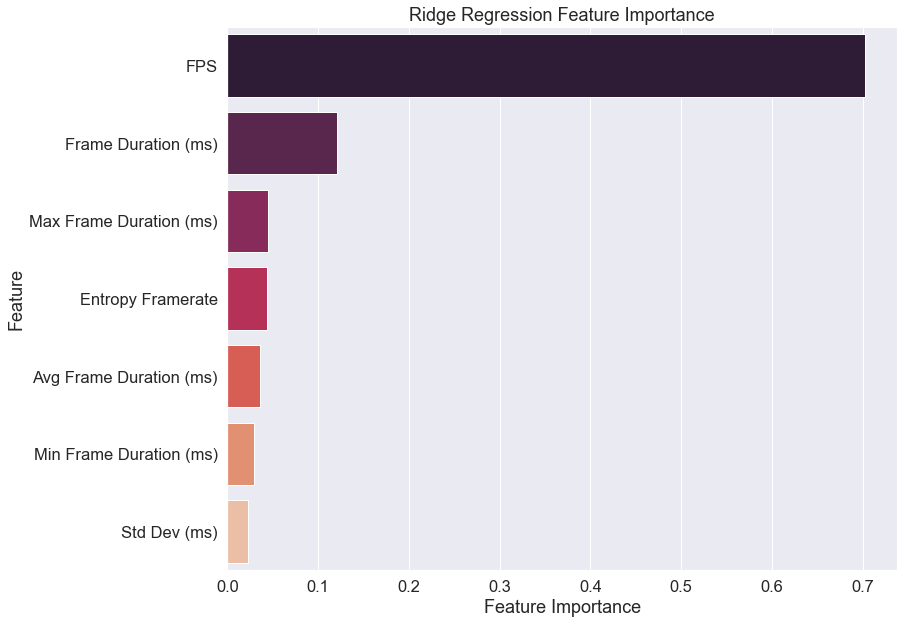

In [122]:
plt.figure(figsize = (12, 10))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [123]:
# Calculate permutation importance
perm_importance_ridge = permutation_importance(ridge, X_train, y_train, n_repeats=10, random_state=42)

In [124]:
# Create a DataFrame to store the feature importance scores and names
feature_importance_ridge = pd.DataFrame({'Feature': X.columns, 'Importance': perm_importance_enet.importances_mean})
feature_importance_ridge

,Feature,Importance
0,FPS,1.764391
1,Frame Duration (ms),0.041722
2,Min Frame Duration (ms),0.002163
3,Max Frame Duration (ms),0.000143
4,Avg Frame Duration (ms),0.005969
5,Std Dev (ms),0.000000
6,Entropy Framerate,0.007277


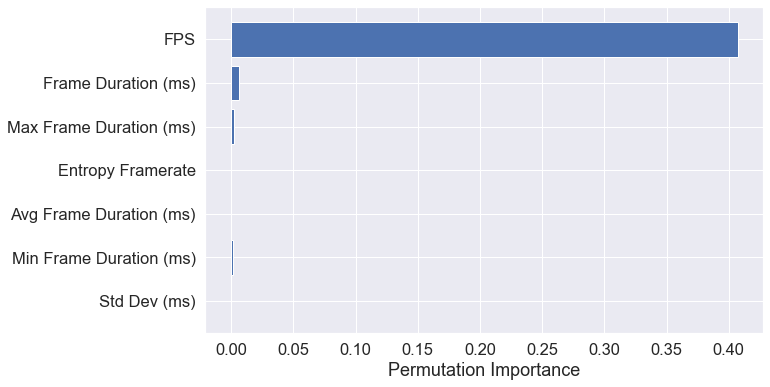

In [125]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = perm_importance_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [126]:
#shap

In [127]:
import shap

Exact explainer: 2068it [00:50, 34.60it/s]                          


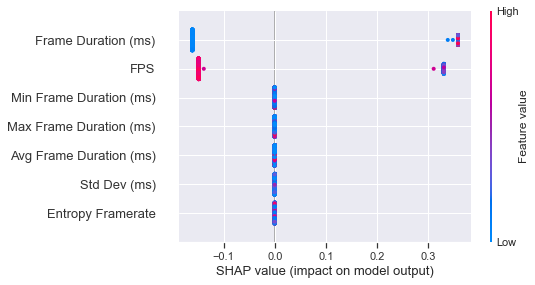

In [128]:
# Train a random forest regressor model
rf = RandomForestRegressor(random_state=100)
rf.fit(X_train, y_train)

# Calculate Shapley value feature importance
explainer = shap.Explainer(rf.predict, X_train)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test, feature_names=X.columns)